In [366]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_score
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

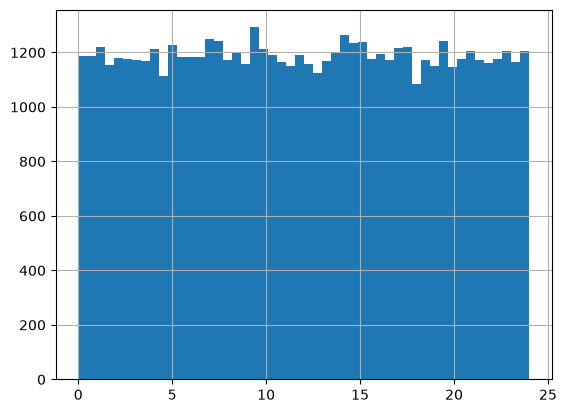

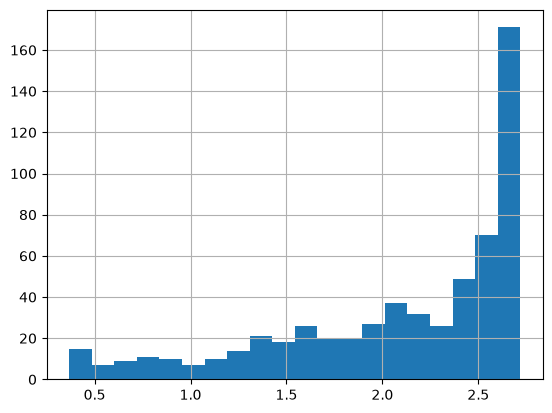

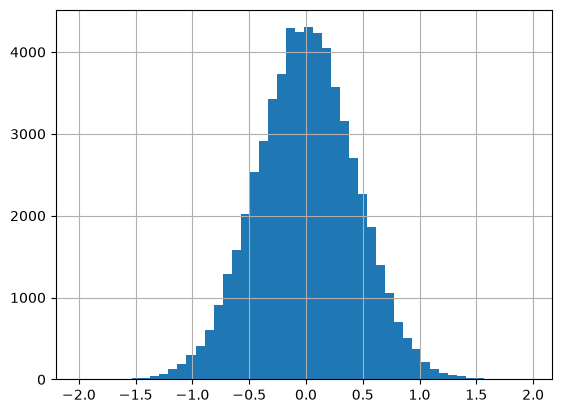

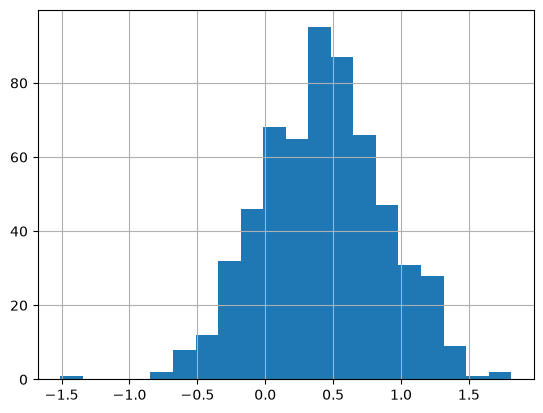

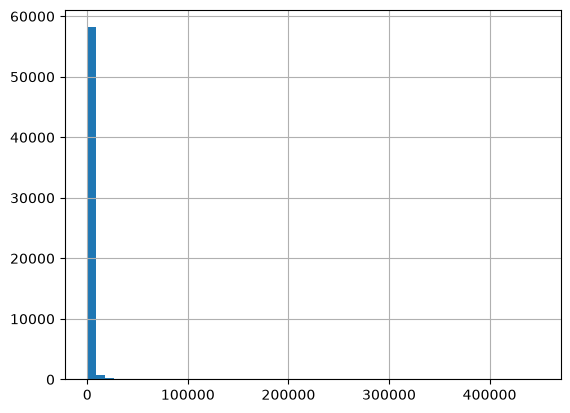

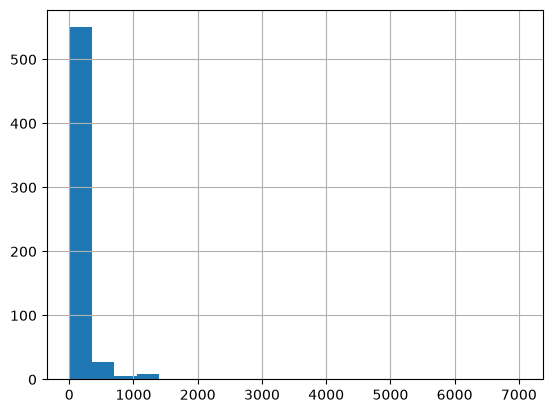

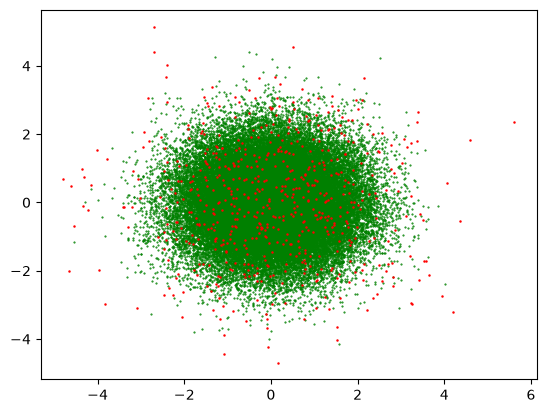

In [367]:
train = pd.read_csv("train.csv")
train[train["target"] == 0]["hour"].hist(bins=50)
plt.show()
np.pow(np.e, np.cos(2 * np.pi * train[train["target"] == 1]["hour"] / 24)).hist(bins=20)
plt.show()
np.log10(train[train["target"] == 0]["amount"] / train[train["target"] == 0]["customer_mean_amount"]).hist(bins=50)
plt.show()
np.log10(train[train["target"] == 1]["amount"] / train[train["target"] == 1]["customer_mean_amount"]).hist(bins=20)
plt.show()
(train[train["target"] == 0]["seconds_since_previous"]).hist(bins=50)
plt.show()
(train[train["target"] == 1]["seconds_since_previous"]).hist(bins=20)
plt.show()
plt.scatter(train[train["target"] == 0]["location_dx"], train[train["target"] == 0]["location_dy"], color="green", s = 0.25)
plt.scatter(train[train["target"] == 1]["location_dx"], train[train["target"] == 1]["location_dy"], color="red", s = 0.6)
plt.show()

In [368]:
train["dist"] = np.sqrt(train["location_dx"] ** 2 + train["location_dy"] ** 2)
train["diff"] = (train["amount"] / train["customer_mean_amount"])
train["hour_cos"] = np.pow(np.e, np.cos(2 * np.pi * train["hour"] / 24))
train["hour_sin"] = np.pow(np.e, np.sin(2 * np.pi * train["hour"] / 24))
train["seconds_since_previous"] = np.log10(train["seconds_since_previous"])
features = ["dist", "hour_cos", "hour_sin", "diff", "seconds_since_previous"]
y_train = train["target"]
X_train = np.c_[np.ones(len(train)), scaler.fit_transform(np.array(train[features]))]

In [369]:

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def grad_step(X, w, y, lr):
    p = sigmoid(X @ w)
    return w - (lr * X.T @ (p - y) / len(y))

def log_loss(X, w, y):
    p = sigmoid(X @ w)
    p = np.clip(p, 1e-15, 1 - 1e-15)
    return (-1 / len(y)) * np.sum(y @ np.log(p) + (1 - y) @ np.log(1 - p))


def fit(X, y, lr, n_iter):
    w = np.ones(X.shape[1])
    precisions = []
    loss = []
    for i in range(n_iter):
        precisions.append(precision_score(y, sigmoid(X @ w) > 0.3))
        loss.append(log_loss(X, w, y))
        w = grad_step(X, w, y, lr)
    return w, precisions, loss

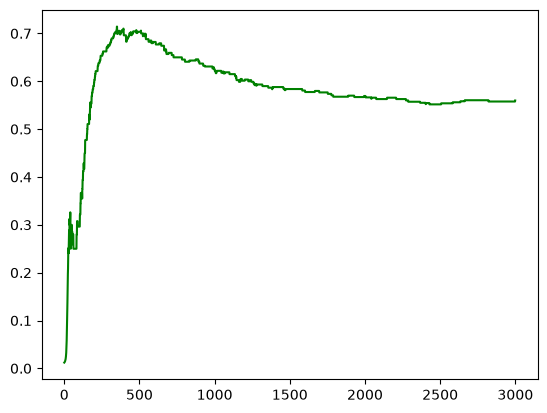

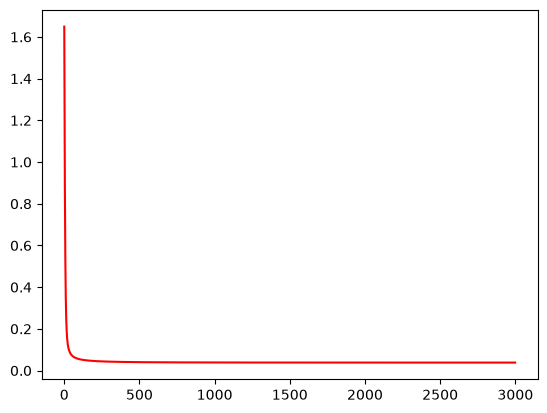

In [370]:
w_train, a_train, l_train = fit(X_train, y_train, 0.5, 3000)
plt.plot(a_train, color="green")
plt.show()
plt.plot(l_train, color="red")
plt.show()

In [371]:
validation = pd.read_csv("validation.csv")
validation["dist"] = np.sqrt(validation["location_dx"] ** 2 + validation["location_dy"] ** 2)
validation["diff"] = np.log(validation["amount"] / validation["customer_mean_amount"])
validation["hour_cos"] = np.pow(np.e, np.cos(2 * np.pi * validation["hour"] / 24))
validation["hour_sin"] = np.pow(np.e, np.sin(2 * np.pi * validation["hour"] / 24))
validation["seconds_since_previous"] = np.log10(validation["seconds_since_previous"])
X_validation = np.c_[np.ones(len(validation)), scaler.fit_transform(np.array(validation[features]))]
target_validation = (sigmoid(X_validation@w_train) > 0.1).astype(int)
submission_validation = pd.DataFrame(columns=["id", "target"])
submission_validation["target"] = target_validation
submission_validation["id"] = validation["id"]
submission_validation.to_csv("submission_validation.csv", index=False)

In [372]:
test = pd.read_csv("test.csv")
test["dist"] = np.sqrt(test["location_dx"] ** 2 + test["location_dy"] ** 2)
test["diff"] = (test["amount"] / test["customer_mean_amount"])
test["hour_cos"] = np.pow(np.e, np.cos(2 * np.pi * test["hour"] / 24))
test["hour_sin"] = np.pow(np.e, np.sin(2 * np.pi * test["hour"] / 24))
test["seconds_since_previous"] = np.log10(test["seconds_since_previous"])
X_test = np.c_[np.ones(len(test)), scaler.fit_transform(np.array(test[features]))]
target_test = (sigmoid(X_test@w_train) > 0.1).astype(int)
submission_test = pd.DataFrame(columns=["id", "target"])
submission_test["target"] = target_test
submission_test["id"] = test["id"]
submission_test.to_csv("submission.csv", index=False)